<a href="https://colab.research.google.com/github/TejasDharmale/Bayesian-machine-learning-assignment/blob/main/Bayesian_machine_learning_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q jaxopt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.4/172.4 kB 539.0 kB/s eta 0:00:00


In [19]:
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import jax.random as jr
import jaxopt
from jax import flatten_util
from jax.scipy.linalg import solve_triangular
jax.config.update('jax_enable_x64', True)

### 1.1 Test function and initial observations


In [ ]:
def f(x):
    x = x[:, 0]
    return jnp.sin(3 * jnp.pi * x) + 0.5 * jnp.sin(7 * jnp.pi * x)

key = jr.PRNGKey(0)
key, subkey = jr.split(key)
X = jr.uniform(subkey, shape=(5, 1), minval=0.0, maxval=1.0)
y = f(X)

X_test = jnp.linspace(0, 1, 200)[:, None]

### 1.2 Gaussian Process: kernel, posterior and prediction

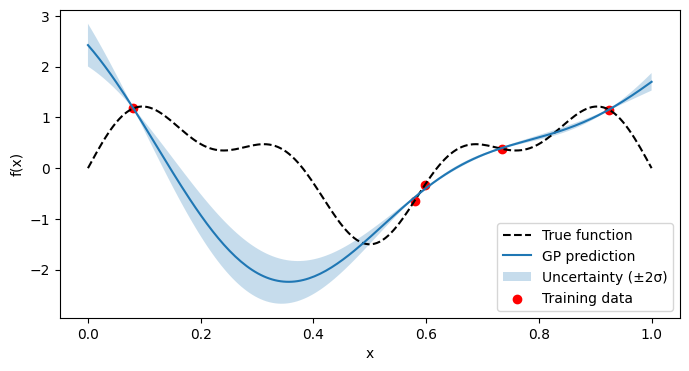

In [ ]:

def k_SE(x1, x2, params):
    length_scale, signal_std = params

    # Calculate squared distances
    diff = x1[:, None, :] - x2[None, :, :]
    distance = jnp.sum(diff ** 2, axis=-1)

    # Return the squared exponential kernel
    return signal_std ** 2 * jnp.exp(-distance / (2 * length_scale ** 2))


def gp_posterior(train_data, X_test, kernel, params, obs_noise=0.01):
    X_train, y_train = train_data
    n = len(X_train)

    # Kernel matrix for training points
    K = kernel(X_train, X_train, params)
    K = K + obs_noise ** 2 * jnp.eye(n)

    # Kernel matrix between training and test points
    K_s = kernel(X_train, X_test, params)

    # Kernel matrix for test points
    K_ss = kernel(X_test, X_test, params)

    # Cholesky decomposition
    L = jnp.linalg.cholesky(K)

    temp = solve_triangular(L, y_train, lower=True)
    alpha = solve_triangular(L.T, temp, lower=False)

    # Calculate the predicted mean
    mean = K_s.T @ alpha
    mean = mean.squeeze()

    # Calculate the predicted covariance
    v = solve_triangular(L, K_s, lower=True)
    covariance = K_ss - v.T @ v

    return mean, covariance


# Set kernel parameters
params = (jnp.array([0.3]), jnp.array([1.0]))

# Predict the mean and uncertainty
mu, cov = gp_posterior((X, y), X_test, k_SE, params)

# Calculate standard deviation
sigma = jnp.sqrt(jnp.clip(jnp.diag(cov), 0.0))


fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(X_test[:, 0], f(X_test), 'k--', label='True function')
ax.plot(X_test[:, 0], mu, label='GP prediction')

ax.fill_between(
    X_test[:, 0],
    mu - 2 * sigma,
    mu + 2 * sigma,
    alpha=0.25,
    label='Uncertainty (±2σ)'
)

ax.scatter(X[:, 0], y, color='red', label='Training data')

ax.set_xlabel('x')
ax.set_ylabel('f(x)')
ax.legend()
plt.show()


#UCB acquisition

In [ ]:
def ucb(mu, sigma, beta):
    return mu + beta * sigma

β=0.0: next point x = 0.000
β=2.0: next point x = 0.000
β=10.0: next point x = 0.000


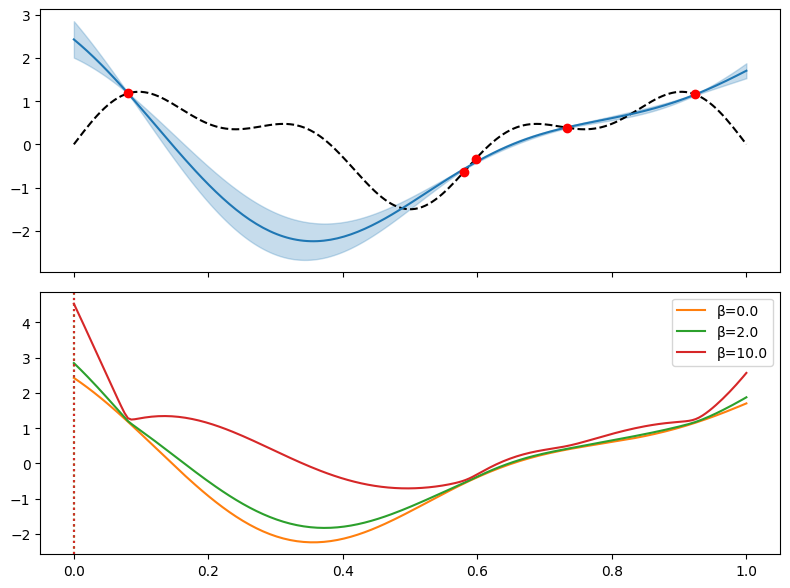

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# top: the GP from Block 1
axes[0].plot(X_test[:, 0], f(X_test), 'k--')
axes[0].plot(X_test[:, 0], mu, 'C0')
axes[0].fill_between(X_test[:, 0], mu - 2*sigma, mu + 2*sigma, color='C0', alpha=0.25)
axes[0].scatter(X[:, 0], y, c='red', zorder=3)

# bottom: the UCB score for three β values
for beta, c in [(0.0, 'C1'), (2.0, 'C2'), (10.0, 'C3')]:
    a = ucb(mu, sigma, beta)
    i = jnp.argmax(a)                       # index of the best score
    axes[1].plot(X_test[:, 0], a, c, label=f'β={beta}')
    axes[1].axvline(X_test[i, 0], color=c, ls=':')
    print(f'β={beta}: next point x = {float(X_test[i, 0]):.3f}')

axes[1].legend()
plt.tight_layout(); plt.show()

### 3.1 The Bayesian optimization loop

In [ ]:

def run_bo(f, X_grid, n_init, n_iter, beta, params, key, obs_noise=0.01):

    key, subkey = jr.split(key)
    idx = jr.choice(subkey, X_grid.shape[0], (n_init,), replace=False)

    X = X_grid[idx]
    y = f(X)
    best_so_far = [float(jnp.max(y))]

    for _ in range(n_iter):
        mu, cov = gp_posterior((X, y), X_grid, k_SE, params, obs_noise)
        sigma = jnp.sqrt(jnp.clip(jnp.diag(cov), 0.0))

        x_next = X_grid[jnp.argmax(ucb(mu, sigma, beta))][None, :]
        y_next = f(x_next)

        X = jnp.concatenate([X, x_next])
        y = jnp.concatenate([y, y_next])
        best_so_far.append(float(jnp.max(y)))

    return X, y, jnp.array(best_so_far)


β=0.0, seed=1: final regret = 0.179
   picks: [0.94, 0.0, 0.82, 0.14, 1.0, 0.16, 0.16, 0.16, 0.85, 0.85, 0.85, 0.85, 0.85, 0.85, 0.85]
β=0.0, seed=2: final regret = 0.000
   picks: [1.0, 0.08, 0.18, 0.0, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9]
β=0.0, seed=3: final regret = 0.221
   picks: [0.48, 1.0, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86]
β=2.0, seed=1: final regret = 0.179
   picks: [1.0, 0.0, 0.82, 0.14, 0.16, 0.16, 0.16, 0.16, 0.76, 0.16, 0.16, 0.16, 0.16, 0.16, 0.16]
β=2.0, seed=2: final regret = 0.002
   picks: [0.0, 1.0, 0.19, 0.87, 0.88, 0.88, 0.88, 0.88, 0.88, 0.88, 0.88, 0.88, 0.88, 0.88, 0.88]
β=2.0, seed=3: final regret = 0.179
   picks: [1.0, 0.51, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86, 0.86]


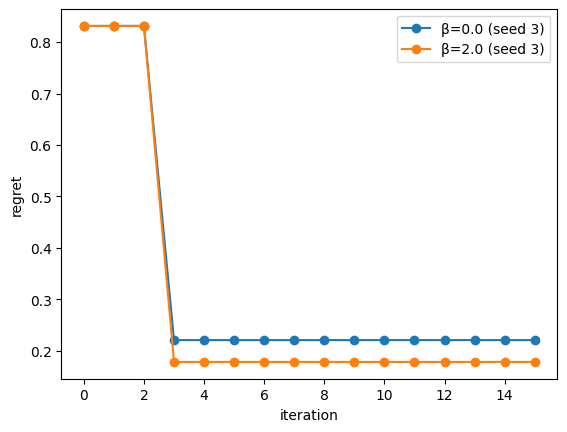

In [ ]:
X_grid = jnp.linspace(0, 1, 200)[:, None]
f_max = float(jnp.max(f(X_grid)))     # known only because f is a toy

for beta in [0.0, 2.0]:
    for seed in [1, 2, 3]:
        Xb, yb, best = run_bo(f, X_grid, n_init=3, n_iter=15, beta=beta,
                              params=params, key=jr.PRNGKey(seed))
        print(f'β={beta}, seed={seed}: final regret = {f_max - float(best[-1]):.3f}')
        print('   picks:', [round(v, 2) for v in Xb[3:, 0].tolist()])

    plt.plot(f_max - best, 'o-', label=f'β={beta} (seed 3)')
plt.xlabel('iteration'); plt.ylabel('regret'); plt.legend(); plt.show()

### 3b. Fitting the GP hyperparameters with the marginal likelihood

In [ ]:
# 3b.1 Negative log marginal likelihood
def neg_log_marginal_likelihood(ell, sf, X, y, obs_noise=0.01):
    n = len(X)
    K = k_SE(X, X, (ell, sf)) + (obs_noise**2 + 1e-6) * jnp.eye(n)

    L = jnp.linalg.cholesky(K)
    alpha = solve_triangular(L.T, solve_triangular(L, y, lower=True), lower=False)

    return 0.5 * y @ alpha + jnp.sum(jnp.log(jnp.diag(L))) + 0.5 * n * jnp.log(2 * jnp.pi)

In [ ]:
# 3b.2 Fitting the hyperparameters by grid search
ELL_GRID = jnp.logspace(-2, 0, 40)
SF_GRID = jnp.logspace(-1, 1, 30)

def fit_hyperparams(X, y, obs_noise=0.01):
    best_loss = jnp.inf
    best_params = None

    for ell in ELL_GRID:
        for sf in SF_GRID:
            loss = neg_log_marginal_likelihood(ell, sf, X, y, obs_noise)

            if jnp.isfinite(loss) and loss < best_loss:
                best_loss = loss
                best_params = (ell, sf)

    return (jnp.array([best_params[0]]), jnp.array([best_params[1]]))

Best lengthscale: 0.10608183551394483
Best signal std: 0.9236708571873862


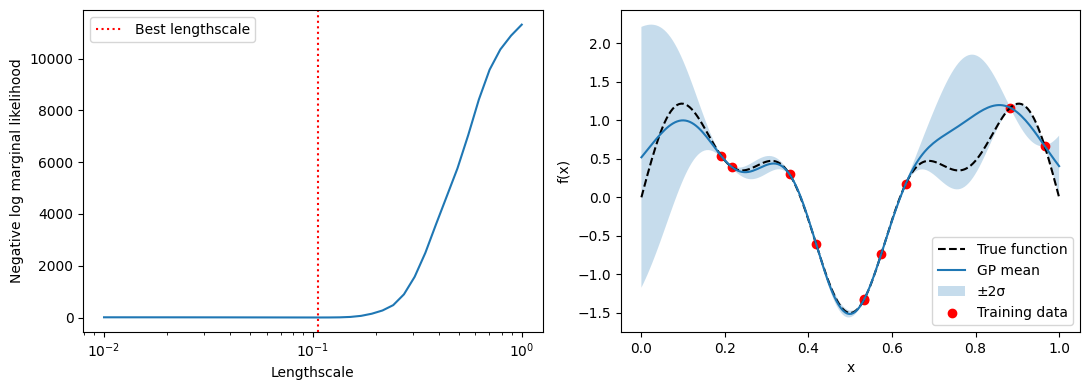

In [ ]:
# 3b.3 Visualising the fitted GP
X10 = jr.uniform(jr.PRNGKey(0), (10, 1))
y10 = f(X10)

# Fit the best hyperparameters
best_params = fit_hyperparams(X10, y10)
ell, sf = best_params

print("Best lengthscale:", float(ell[0]))
print("Best signal std:", float(sf[0]))

# Calculate NLML for different lengthscales (sf fixed at 1.0)
nlml = jax.vmap(
    lambda e: neg_log_marginal_likelihood(e, 1.0, X10, y10)
)(ELL_GRID)

# GP prediction
mu, cov = gp_posterior((X10, y10), X_test, k_SE, best_params)
sigma = jnp.sqrt(jnp.clip(jnp.diag(cov), 0.0))

# Plot results
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].semilogx(ELL_GRID, nlml)
ax[0].axvline(float(ell[0]), color='red', linestyle=':', label='Best lengthscale')
ax[0].set_xlabel('Lengthscale')
ax[0].set_ylabel('Negative log marginal likelihood')
ax[0].legend()

ax[1].plot(X_test[:, 0], f(X_test), 'k--', label='True function')
ax[1].plot(X_test[:, 0], mu, label='GP mean')
ax[1].fill_between(X_test[:, 0], mu - 2*sigma, mu + 2*sigma, alpha=0.25, label='±2σ')
ax[1].scatter(X10[:, 0], y10, color='red', label='Training data')
ax[1].set_xlabel('x')
ax[1].set_ylabel('f(x)')
ax[1].legend()

plt.tight_layout()
plt.show()

### 4. Comparing acquisition functions: greedy, UCB and Thompson sampling

greedy: mean final regret = 0.303, found max in 6/10
ucb: mean final regret = 0.000, found max in 10/10
thompson: mean final regret = 0.000, found max in 10/10


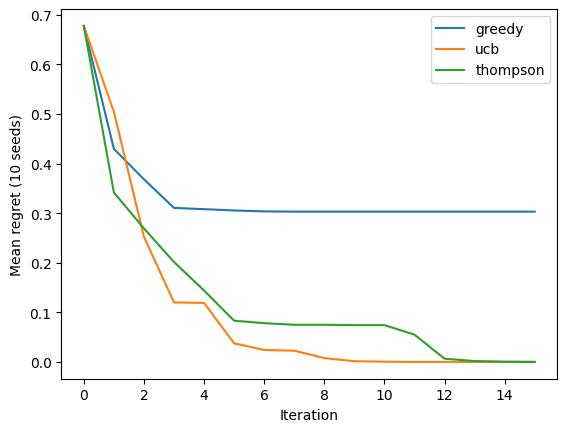

In [ ]:
# Compare Greedy, UCB and Thompson Sampling
def run_bo_method(f, X_grid, method, n_init, n_iter, key, beta=2.0, obs_noise=0.01):
    key, subkey = jr.split(key)
    idx = jr.choice(subkey, len(X_grid), (n_init,), replace=False)

    X = X_grid[idx]
    y = f(X)
    best = [float(jnp.max(y))]

    for _ in range(n_iter):
        params = fit_hyperparams(X, y, obs_noise)
        mu, cov = gp_posterior((X, y), X_grid, k_SE, params, obs_noise)
        sigma = jnp.sqrt(jnp.clip(jnp.diag(cov), 0.0))

        key, subkey = jr.split(key)

        if method == "greedy":
            score = mu
        elif method == "ucb":
            score = mu + beta * sigma
        else:
            score = jr.multivariate_normal(
                subkey, mu, cov + 1e-6 * jnp.eye(len(mu)), method="eigh"
            )

        x_next = X_grid[jnp.argmax(score)][None, :]
        X = jnp.concatenate([X, x_next])
        y = jnp.concatenate([y, f(x_next)])

        best.append(float(jnp.max(y)))

    return jnp.array(best)


# Run each method with 10 random seeds
for method in ["greedy", "ucb", "thompson"]:
    regrets = []

    for seed in range(10):
        best_values = run_bo_method(
            f, X_grid, method, 3, 15, jr.PRNGKey(seed)
        )
        regrets.append(f_max - best_values)

    regrets = jnp.stack(regrets)
    mean_regret = regrets.mean(axis=0)

    print(
        f"{method}: mean final regret = {float(mean_regret[-1]):.3f}, "
        f"found max in {int((regrets[:, -1] < 0.01).sum())}/10"
    )

    plt.plot(mean_regret, label=method)

plt.xlabel("Iteration")
plt.ylabel("Mean regret (10 seeds)")
plt.legend()
plt.show()

### 5. Effect of β: from exploitation to exploration

Beta=-1.0: final regret=0.366, found max=5/10, regret at step 5=0.366
Beta=0.0: final regret=0.303, found max=6/10, regret at step 5=0.305
Beta=0.5: final regret=0.074, found max=9/10, regret at step 5=0.076
Beta=2.0: final regret=0.000, found max=10/10, regret at step 5=0.038
Beta=5.0: final regret=0.000, found max=10/10, regret at step 5=0.138
Beta=10.0: final regret=0.000, found max=10/10, regret at step 5=0.169


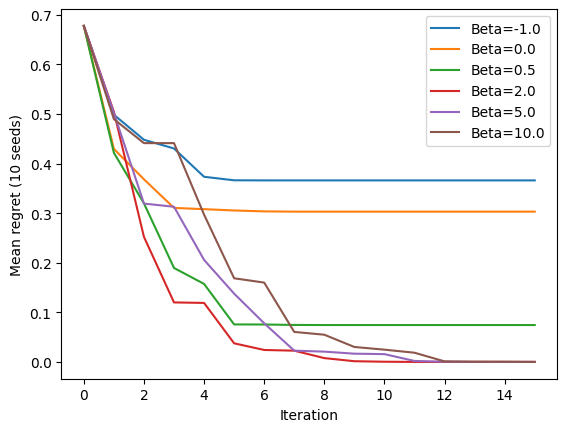

In [ ]:
# Test different beta values for UCB
for beta in [-1.0, 0.0, 0.5, 2.0, 5.0, 10.0]:
    regrets = []

    for seed in range(10):
        best_values = run_bo_method(
            f, X_grid, "ucb", 3, 15, jr.PRNGKey(seed), beta=beta
        )
        regrets.append(f_max - best_values)

    regrets = jnp.stack(regrets)
    mean_regret = regrets.mean(axis=0)

    print(
        f"Beta={beta}: final regret={float(mean_regret[-1]):.3f}, "
        f"found max={int((regrets[:, -1] < 0.01).sum())}/10, "
        f"regret at step 5={float(mean_regret[5]):.3f}"
    )

    plt.plot(mean_regret, label=f"Beta={beta}")

plt.xlabel("Iteration")
plt.ylabel("Mean regret (10 seeds)")
plt.legend()
plt.show()

### 6. Bayesian optimization on the Ackley function (2D)

In [ ]:
def run_bo_method(f, X_grid, method, n_init, n_iter, key, beta=2.0, obs_noise=0.01, norm=False):
    key, subkey = jr.split(key)
    idx = jr.choice(subkey, len(X_grid), (n_init,), replace=False)

    X = X_grid[idx]
    y = f(X)
    best = [float(jnp.max(y))]

    for _ in range(n_iter):
        yn = (y - y.mean()) / (y.std() + 1e-8) if norm else y
        params = fit_hyperparams(X, yn, obs_noise)
        mu, cov = gp_posterior((X, yn), X_grid, k_SE, params, obs_noise)
        sigma = jnp.sqrt(jnp.clip(jnp.diag(cov), 0.0))

        key, subkey = jr.split(key)

        if method == "greedy":
            score = mu
        elif method == "ucb":
            score = mu + beta * sigma
        else:
            score = jr.multivariate_normal(
                subkey, mu, cov + 1e-6 * jnp.eye(len(mu)), method="eigh"
            )

        x_next = X_grid[jnp.argmax(score)][None, :]
        X = jnp.concatenate([X, x_next])
        y = jnp.concatenate([y, f(x_next)])

        best.append(float(jnp.max(y)))

    return jnp.array(best)

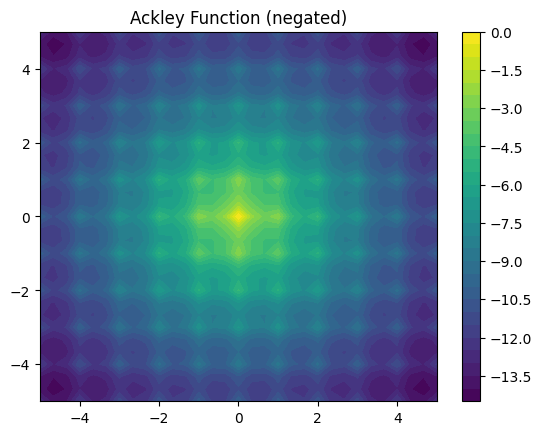

greedy: final regret = 1.00, found max = 3/5
ucb: final regret = 2.12, found max = 1/5
thompson: final regret = 3.34, found max = 0/5


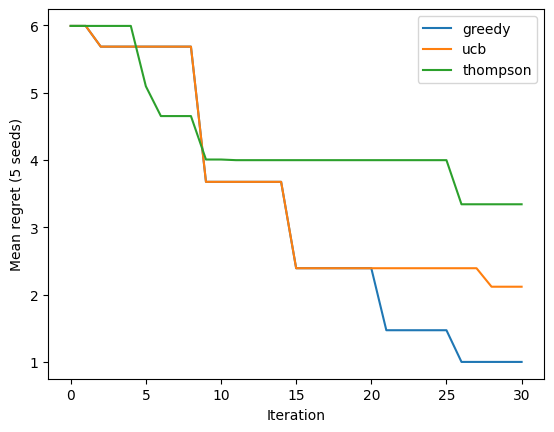

In [ ]:
# Ackley function (2D)
def ackley(X):
    x1, x2 = X[:, 0], X[:, 1]

    term1 = -20 * jnp.exp(-0.2 * jnp.sqrt((x1**2 + x2**2) / 2))
    term2 = -jnp.exp((jnp.cos(2*jnp.pi*x1) + jnp.cos(2*jnp.pi*x2)) / 2)

    return -(term1 + term2 + 20 + jnp.e)


# Create a grid of candidate points
g = jnp.linspace(-5, 5, 31)
G1, G2 = jnp.meshgrid(g, g)
X2 = jnp.stack([G1.ravel(), G2.ravel()], axis=1)

# Find the maximum value
a_max = jnp.max(ackley(X2))

# Plot the Ackley function
plt.contourf(G1, G2, ackley(X2).reshape(31, 31), levels=30)
plt.colorbar()
plt.title("Ackley Function (negated)")
plt.show()



for method in ["greedy", "ucb", "thompson"]:
    regrets = []

    for seed in range(5):
        best_values = run_bo_method(
            ackley, X2, method, 5, 30, jr.PRNGKey(seed)
        )
        regrets.append(a_max - best_values)

    regrets = jnp.stack(regrets)
    mean_regret = regrets.mean(axis=0)

    print(
        f"{method}: final regret = {float(mean_regret[-1]):.2f}, "
        f"found max = {int((regrets[:, -1] < 0.01).sum())}/5"
    )

    plt.plot(mean_regret, label=method)

plt.xlabel("Iteration")
plt.ylabel("Mean regret (5 seeds)")
plt.legend()
plt.show()

### 7. Kernel choice and fully Bayesian hyperparameters

In [21]:
# Matérn 5/2 kernel
def k_matern52(x1, x2, params):
    ell, sf = params

    diff = x1[:, None, :] - x2[None, :, :]
    distance = jnp.sqrt(jnp.sum(diff**2, axis=-1) + 1e-12) / ell

    return sf**2 * (1 + jnp.sqrt(5)*distance + 5*distance**2/3) * jnp.exp(-jnp.sqrt(5)*distance)


# Negative log marginal likelihood
def nlml(ell, sf, X, y, kernel, obs_noise=0.01):
    K = kernel(X, X, (ell, sf))
    K += (obs_noise**2 + 1e-6) * jnp.eye(len(X))

    L = jnp.linalg.cholesky(K)
    temp = solve_triangular(L, y, lower=True)
    alpha = solve_triangular(L.T, temp, lower=False)

    data_fit = 0.5 * y @ alpha
    complexity = jnp.sum(jnp.log(jnp.diag(L)))
    constant = 0.5 * len(X) * jnp.log(2*jnp.pi)

    return data_fit + complexity + constant



for name, kernel in [("SE", k_SE), ("Matérn 5/2", k_matern52)]:
    scores = []

    for ell in ELL_GRID:
        row = []
        for sf in SF_GRID:
            loss = nlml(ell, sf, X10, y10, kernel)
            row.append(loss)
        scores.append(row)

    scores = jnp.array(scores)
    best_index = jnp.argmin(scores)
    i, j = jnp.unravel_index(best_index, scores.shape)

    print(
        f"{name}: best lengthscale = {float(ELL_GRID[i]):.3f}, "
        f"best signal std = {float(SF_GRID[j]):.3f}, "
        f"NLML = {float(scores[i, j]):.2f}"
    )

SE: best lengthscale = 0.106, best signal std = 0.924, NLML = 2.77
Matérn 5/2: best lengthscale = 0.134, best signal std = 0.924, NLML = 3.42


90% interval: [0.0380851  0.12445675]


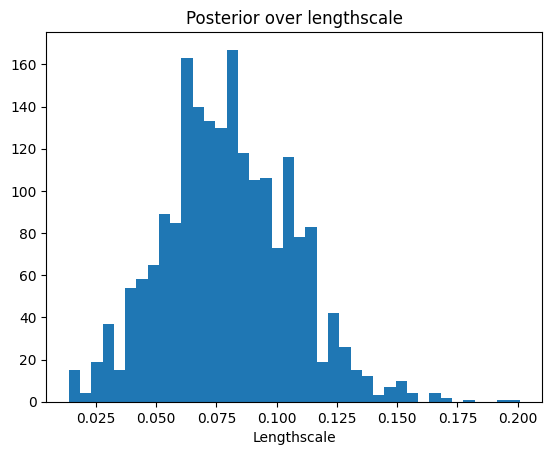

In [22]:
# Fully Bayesian GP using Metropolis-Hastings
X5 = jr.uniform(jr.PRNGKey(3), (5, 1))
y5 = f(X5)

def log_posterior(theta):
    ell, sf = jnp.exp(theta)
    prior = -0.5 * jnp.sum((theta - jnp.log(jnp.array([0.2, 1.0])))**2)
    return -nlml(ell, sf, X5, y5, k_SE) + prior

key = jr.PRNGKey(0)
theta = jnp.log(jnp.array([0.2, 1.0]))
samples = []

for _ in range(3000):
    key, k1, k2 = jr.split(key, 3)
    proposal = theta + 0.5 * jr.normal(k1, (2,))

    if jnp.log(jr.uniform(k2)) < log_posterior(proposal) - log_posterior(theta):
        theta = proposal

    samples.append(jnp.exp(theta))

ells = jnp.stack(samples[1000:])[:, 0]
print("90% interval:", jnp.percentile(ells, jnp.array([5, 95])))

plt.hist(ells, bins=40)
plt.xlabel("Lengthscale")
plt.title("Posterior over lengthscale")
plt.show()